# Pathology prediction from the EEG: status and diagnosis groups

📄 **[PDF version](pathology_prediction.pdf)**

This notebook reads the classification side of the multi-task brain-age models: how well the EEG predicts
the **normal/abnormal status** and **13 NEDC diagnosis groups** of a TUH recording. For every target it reports
the threshold-free ranking (ROC-AUC, PR-AUC), the **best F1** over all thresholds with its bootstrap interval,
the **errors** (false positives and negatives) at that threshold, and the **ROC and precision-recall curves**.

It compares four runs on **one identical split** (Exp4mtbal's recorded `data_split.json`: 27,616 train, 3,422
validation and 274 TUAB-test recordings):
* two runs that also predict age (`Exp4mt`, `Exp4mtbal`, Table 2.10 of `brain_age_research_summary.ipynb`);
* two **classification-only** runs without the age prediction: `Exp4cls` (EEG only) and `Exp4clsage` (the
  recording's known age as an extra encoder input).

Per-recording probabilities come from `scripts/eval_multitask_classification.py`
(`docs/data/multitask_class_predictions.csv.gz`); every metric is computed here from them by
`labram/eval/binary_metrics.py`.

In [1]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

if not any(os.path.isdir(os.path.join(p, "labram")) for p in sys.path):
    sys.path.insert(0, os.path.abspath(".."))
REPO = next(p for p in sys.path if os.path.isdir(os.path.join(p, "labram")))
warnings.filterwarnings("ignore")
from labram.eval.age_plots import assert_max_columns, figure_heading, numbered_table, panel_labels
from labram.eval.binary_metrics import classification_table
from labram.eval.pathology_plots import f1_interval_figure, roc_pr_figure

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 220)

PREDS = pd.read_csv(os.path.join(REPO, "docs/data/multitask_class_predictions.csv.gz"))
ALL_RUNS = ["Exp4mt", "Exp4mtbal", "Exp4cls", "Exp4clsage"]
RUNS = [r for r in ALL_RUNS if r in set(PREDS.run)]
TARGETS = list(dict.fromkeys(PREDS.target))
TABLE = classification_table(PREDS, n_boot=1000, seed=0)       # Eqs. (2.1)-(2.8)


def finish(fig, axes=None):
    fig.tight_layout()
    if axes is not None and len(axes) > 1:
        panel_labels(axes)
    assert_max_columns(fig)
    plt.show()


print("runs scored:", RUNS)

runs scored: ['Exp4mt', 'Exp4mtbal', 'Exp4cls', 'Exp4clsage']


## 1. Runs and labels

### Table 1.1. The runs

All four runs share everything except the columns below: `Exp4noearEEG`'s setup (19 channels without
A1/A2/T1/T2, EEG-only input, LaBraM-base start, 8 epochs with 2 warm-up, 5 training minutes per recording per
epoch, mixup, early stopping) and the multi-task head (2 shared layers 256-256, an age branch 128-64-1 and a
classification branch 128-64-14). The classification loss is $0.5\,\mathrm{BCE}_{\mathrm{status}} +
0.5\,L_{\mathrm{path}}$ with $L_{\mathrm{path}}$ the plain (`known`) or class-balanced (`present`) mean BCE over
the diagnosis groups (Eqs. (2.15)–(2.16) of the research summary). `age weight` multiplies the age (Huber) loss
(`loss.age_weight`); at 0 the age branch gets no gradient and the model is a pure classifier. `age input`
`tokens` (`model.age_input=tokens`) feeds the recording's known age (z-scored with the training mean 52.35 and
SD 17.60 years) through a `Linear(1 → 200)` + LayerNorm as one extra token into the transformer, next to the
EEG patch tokens. `selected on` is the validation metric that picks the reported epoch.

| run | age weight | pathology loss | age input | selected on | where |
|---|---|---|---|---|---|
| `Exp4mt` | 1 | known | – | age MAE | SageMaker |
| `Exp4mtbal` | 1 | present (class-balanced) | – | age MAE | local |
| `Exp4cls` | **0** | present | – | pathology macro ROC-AUC | local |
| `Exp4clsage` | **0** | present | **tokens** | pathology macro ROC-AUC | SageMaker |

### Table 1.2. Labels per target

Per target: the recordings whose label is known, the positives among them and their prevalence $\pi$
(Eq. (2.6)), on validation and on TUAB test. A label is unknown when the recording has no status, or for a
group when its session is not in the NEDC clinical sheet; unknown labels are never scored. TUAB test holds only
11 diagnosis-group positives in total, so the groups are judged on validation and test is used for the status.

In [2]:
lab = PREDS[PREDS.run == RUNS[0]].dropna(subset=["y"])
t12 = lab.groupby(["target", "split"]).y.agg(known="size", positives="sum").unstack("split")
t12.columns = [f"{s} {c}" for c, s in t12.columns]
t12 = t12.reindex(TARGETS)[["val known", "val positives", "test known", "test positives"]].fillna(0).astype(int)
t12.insert(2, "val prevalence %", 100 * t12["val positives"] / t12["val known"])
display(numbered_table(t12, "1.2", "Labels per target"))

,val known,val positives,val prevalence %,test known,test positives
target,,,,,
status_abnormal,3064,1676,54.70,274,125
clinical_seizure,2991,185,6.19,268,0
electrographic_seizure,2991,11,0.37,268,0
epilepsy,2991,46,1.54,268,0
stroke,2991,93,3.11,268,1
tbi,2991,50,1.67,268,0
substance,2991,103,3.44,268,10
bipolar,2991,31,1.04,268,7
anxiety,2991,10,0.33,268,0


## 2. Metrics

For one target, recording $i$ of a split has the label $y_i \in \{0, 1\}$ (known labels only) and the score
$p_i$, the mean of its windows' sigmoid probabilities (as in training's per-recording metrics). Predicting
positive when $p_i \ge t$ gives, at threshold $t$, the true and false positives and negatives
$\mathrm{TP}(t), \mathrm{FP}(t), \mathrm{FN}(t), \mathrm{TN}(t)$ (counts of recordings,
`binary_metrics.py::threshold_metrics`) and

$$ \mathrm{prec}(t) = \frac{\mathrm{TP}}{\mathrm{TP} + \mathrm{FP}}, \qquad
   \mathrm{rec}(t) = \frac{\mathrm{TP}}{\mathrm{TP} + \mathrm{FN}}, \qquad
   \mathrm{spec}(t) = \frac{\mathrm{TN}}{\mathrm{TN} + \mathrm{FP}} \tag{2.1} $$

$$ F_1(t) = \frac{2\,\mathrm{prec}(t)\,\mathrm{rec}(t)}{\mathrm{prec}(t) + \mathrm{rec}(t)} \tag{2.2} $$

(0 when no recording is flagged). The **errors** at $t$ are the error rate and the balanced error

$$ \mathrm{err}(t) = \frac{\mathrm{FP} + \mathrm{FN}}{n}, \qquad
   \mathrm{berr}(t) = 1 - \tfrac{1}{2}\big(\mathrm{rec}(t) + \mathrm{spec}(t)\big) \tag{2.3} $$

with $n$ the known recordings. The **best F1** is the maximum over every distinct score as threshold
(`best_f1_threshold`; ties go to the higher threshold):

$$ t^{\star} = \arg\max_{t \in \{p_i\}} F_1(t), \qquad F_1^{\star} = F_1(t^{\star}) \tag{2.4} $$

$F_1^{\star}$ on a split picks $t^{\star}$ on that split's own labels, so it is optimistic. The honest
operating point on test carries the **validation** threshold over:

$$ F_1^{\mathrm{val}\to\mathrm{test}} = F_1^{\mathrm{test}}\big(t^{\star}_{\mathrm{val}}\big) \tag{2.5} $$

The threshold-free metrics are the ROC-AUC (`sklearn` `roc_auc_score`, the area under
$\mathrm{rec}(t)$ against $1 - \mathrm{spec}(t)$) and the PR-AUC as average precision (`average_precision_score`):

$$ \mathrm{AP} = \sum_k \big(\mathrm{rec}_k - \mathrm{rec}_{k-1}\big)\,\mathrm{prec}_k, \qquad
   \mathbb{E}[\mathrm{AP}_{\mathrm{random}}] = \pi = \frac{1}{n}\sum_i y_i \tag{2.6} $$

over the thresholds $k$ in decreasing order. A random score has AP $\approx \pi$ and ROC-AUC 0.5; flagging
every recording gives $F_1 = 2\pi / (1 + \pi)$, the floor marked in Figure 3.1. With 7–50 positives per rare
group, every metric carries a **95 % stratified bootstrap interval** (`bootstrap_ci`, $B = 1000$, positives and
negatives resampled separately, $t^{\star}$ re-chosen in each resample):

$$ \big[\,q_{0.025}\{m^{(b)}\}_{b=1}^{B},\; q_{0.975}\{m^{(b)}\}_{b=1}^{B}\,\big] \tag{2.7} $$

with $m^{(b)}$ the metric on resample $b$ and $q$ the empirical quantile. The macro value of a metric is its
mean over the 13 groups (status excluded):

$$ m_{\mathrm{macro}} = \frac{1}{13}\sum_{k=1}^{13} m_k \tag{2.8} $$

## 3. Results

### Table 3.1. Ranking quality on validation: ROC-AUC and PR-AUC

Per target and run, on the 3,422 validation recordings (known labels only, Table 1.2): ROC-AUC and PR-AUC
(Eq. (2.6)) with their 95 % bootstrap intervals (Eq. (2.7)) as `value [low, high]`; `prevalence` is the PR-AUC
of a random score. The last row is the macro mean over the 13 groups (Eq. (2.8)).

In [3]:
def ci(v, lo, hi, digits=3):
    return f"{v:.{digits}f} [{lo:.{digits}f}, {hi:.{digits}f}]" if np.isfinite(v) else "–"


def wide(split, cols):
    t = TABLE[TABLE.split == split].set_index(["target", "run"])
    out = pd.DataFrame(index=pd.Index([g for g in TARGETS if g in t.index.get_level_values(0)], name="target"))
    for name, fn in cols:
        for run in RUNS:
            out[f"{name} {run}"] = [fn(t.loc[(g, run)]) if (g, run) in t.index else "–" for g in out.index]
    return out


val = TABLE[TABLE.split == "val"]
t31 = wide("val", [("ROC-AUC", lambda r: ci(r.roc_auc, r.roc_auc_lo, r.roc_auc_hi)),
                   ("PR-AUC", lambda r: ci(r.pr_auc, r.pr_auc_lo, r.pr_auc_hi))])
t31.insert(0, "prevalence", [f"{val[val.target == g].prevalence.iloc[0]:.3f}" for g in t31.index])
groups = val[val.target != "status_abnormal"]
t31.loc["macro (13 groups)"] = ["–"] + [f"{groups[groups.run == r][m].mean():.3f}"
                                        for m in ("roc_auc", "pr_auc") for r in RUNS]
display(numbered_table(t31, "3.1", "Ranking quality on validation"))

,prevalence,ROC-AUC Exp4mt,ROC-AUC Exp4mtbal,ROC-AUC Exp4cls,ROC-AUC Exp4clsage,PR-AUC Exp4mt,PR-AUC Exp4mtbal,PR-AUC Exp4cls,PR-AUC Exp4clsage
target,,,,,,,,,
status_abnormal,0.547,"0.822 [0.806, 0.836]","0.820 [0.804, 0.836]","0.813 [0.797, 0.829]","0.827 [0.812, 0.841]","0.821 [0.802, 0.840]","0.819 [0.799, 0.838]","0.807 [0.786, 0.828]","0.825 [0.806, 0.844]"
clinical_seizure,0.062,"0.778 [0.750, 0.805]","0.789 [0.760, 0.819]","0.783 [0.754, 0.809]","0.785 [0.755, 0.815]","0.180 [0.148, 0.227]","0.204 [0.166, 0.256]","0.183 [0.152, 0.233]","0.183 [0.155, 0.229]"
electrographic_seizure,0.004,"0.963 [0.933, 0.985]","0.962 [0.947, 0.975]","0.964 [0.943, 0.983]","0.983 [0.969, 0.993]","0.083 [0.047, 0.199]","0.051 [0.039, 0.083]","0.106 [0.041, 0.330]","0.231 [0.103, 0.454]"
epilepsy,0.015,"0.740 [0.692, 0.786]","0.680 [0.620, 0.739]","0.698 [0.656, 0.742]","0.709 [0.639, 0.776]","0.030 [0.025, 0.041]","0.024 [0.020, 0.032]","0.024 [0.021, 0.030]","0.034 [0.026, 0.049]"
stroke,0.031,"0.756 [0.706, 0.800]","0.769 [0.720, 0.813]","0.795 [0.751, 0.839]","0.732 [0.683, 0.777]","0.083 [0.067, 0.116]","0.105 [0.077, 0.164]","0.143 [0.107, 0.210]","0.072 [0.058, 0.100]"
tbi,0.017,"0.764 [0.713, 0.813]","0.742 [0.681, 0.799]","0.761 [0.697, 0.823]","0.694 [0.633, 0.757]","0.046 [0.033, 0.086]","0.052 [0.034, 0.111]","0.117 [0.066, 0.230]","0.033 [0.026, 0.050]"
substance,0.034,"0.618 [0.557, 0.674]","0.611 [0.552, 0.666]","0.629 [0.571, 0.684]","0.588 [0.532, 0.644]","0.057 [0.045, 0.078]","0.058 [0.044, 0.088]","0.053 [0.044, 0.069]","0.048 [0.040, 0.065]"
bipolar,0.010,"0.556 [0.471, 0.641]","0.532 [0.448, 0.624]","0.654 [0.560, 0.734]","0.571 [0.479, 0.668]","0.012 [0.010, 0.016]","0.011 [0.009, 0.016]","0.020 [0.013, 0.038]","0.015 [0.011, 0.030]"
anxiety,0.003,"0.740 [0.554, 0.895]","0.770 [0.597, 0.914]","0.734 [0.561, 0.872]","0.744 [0.573, 0.889]","0.031 [0.007, 0.145]","0.035 [0.008, 0.165]","0.012 [0.006, 0.040]","0.019 [0.007, 0.077]"


### Table 3.2. Best F1 and the errors at its threshold, validation

Per target and run: the best F1 $F_1^{\star}$ (Eq. (2.4)) with its 95 % interval (Eq. (2.7)), the threshold
$t^{\star}$ (a probability), precision and recall at it (Eq. (2.1)), the errors as recording counts — false
positives FP and false negatives FN next to the true positives TP — and the error rate and balanced error
(Eq. (2.3)) in percent. The last row per run is the macro mean of $F_1^{\star}$ (Eq. (2.8)).

In [4]:
rows = []
for run in RUNS:
    for g in TARGETS:
        r = val[(val.run == run) & (val.target == g)]
        if r.empty:
            continue
        r = r.iloc[0]
        rows.append({"run": run, "target": g, "best F1": ci(r.best_f1, r.best_f1_lo, r.best_f1_hi),
                     "t*": f"{r.best_threshold:.3g}", "precision": r.best_precision, "recall": r.best_recall,
                     "TP": int(r.best_tp), "FP": int(r.best_fp), "FN": int(r.best_fn),
                     "error %": 100 * r.best_error_rate, "balanced error %": 100 * r.best_balanced_error})
    g = groups[groups.run == run]
    rows.append({"run": run, "target": "macro (13 groups)", "best F1": f"{g.best_f1.mean():.3f}",
                 "precision": g.best_precision.mean(), "recall": g.best_recall.mean(),
                 "error %": 100 * g.best_error_rate.mean(), "balanced error %": 100 * g.best_balanced_error.mean()})
t32 = pd.DataFrame(rows).set_index(["run", "target"])
for c in ("TP", "FP", "FN"):
    t32[c] = t32[c].astype("Int64")
display(numbered_table(t32.round(3), "3.2", "Best F1 and errors, validation"))

### Table 3.3. TUAB test: best F1 and the validation threshold carried over

The 274 TUAB-test recordings, for the targets with test positives: ROC-AUC, the best F1 on test
$F_1^{\star}$ (Eq. (2.4), optimistic: its threshold is chosen on test), and the honest
$F_1^{\mathrm{val}\to\mathrm{test}}$ (Eq. (2.5)) with its errors (FP, FN) and balanced error (Eq. (2.3)). Only the
status has enough test positives (125) to read; the groups have 1–10.

In [5]:
test = TABLE[TABLE.split == "test"]
t33 = test.assign(**{"best F1 (test t*)": test.best_f1, "F1 at val t*": test.fixed_f1,
                     "val t*": test.fixed_threshold.map(lambda v: f"{v:.3g}"), "TP": test.fixed_tp, "FP": test.fixed_fp, "FN": test.fixed_fn,
                     "balanced error % at val t*": 100 * test.fixed_balanced_error}).set_index(["target", "run"])
t33 = t33[["positives", "roc_auc", "best F1 (test t*)", "F1 at val t*", "val t*", "TP", "FP", "FN",
           "balanced error % at val t*"]].rename(columns={"roc_auc": "ROC-AUC"})
t33 = t33.reindex([(g, r) for g in TARGETS for r in RUNS if (g, r) in t33.index])
for c in ("TP", "FP", "FN"):
    t33[c] = t33[c].astype(int)
display(numbered_table(t33.round(3), "3.3", "TUAB test"))

### Figure 3.1. Best F1 per target with its bootstrap interval, validation

$F_1^{\star}$ (Eq. (2.4)) per target and run with its 95 % interval (Eq. (2.7)) on the 3,422 validation
recordings; the number under each target is its positives. (a) Status and the groups with at least 40
positives; (b) the rare groups. The grey bar is the F1 of flagging every recording, $2\pi/(1+\pi)$ (Eq. (2.6)):
a model must clear it to be of any use as a detector.

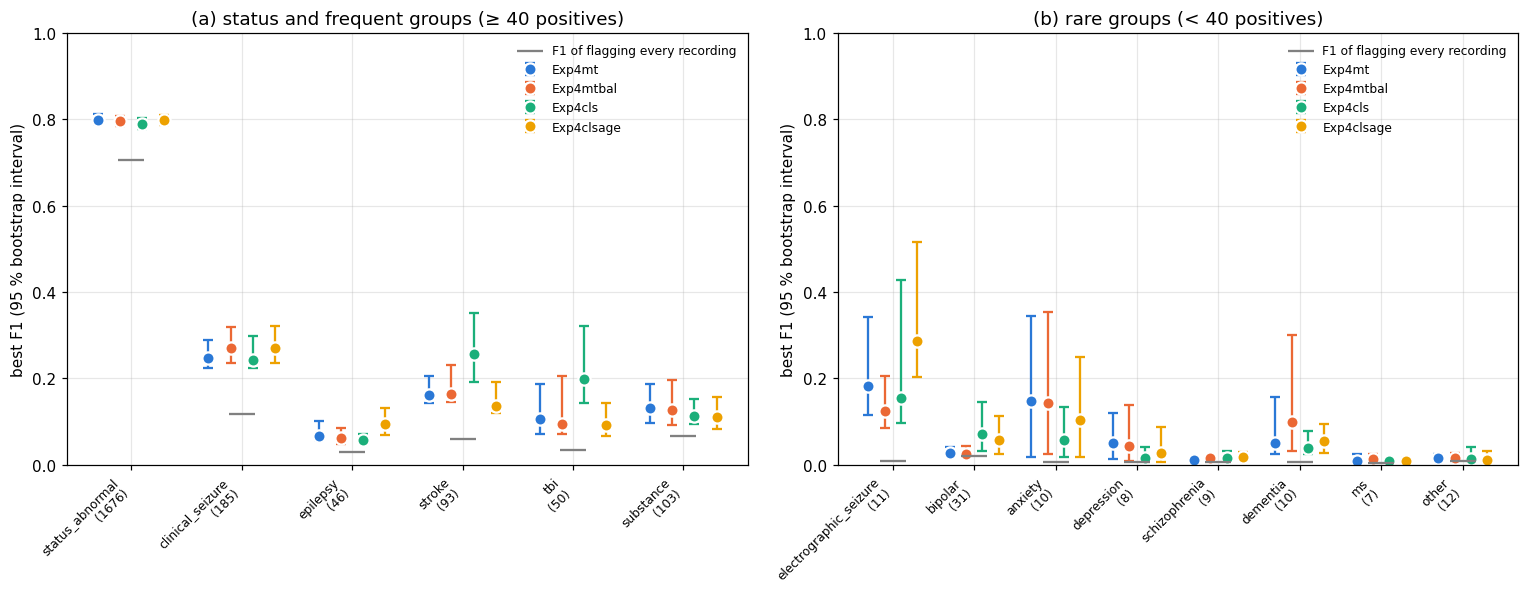

In [6]:
fig, axes = f1_interval_figure(TABLE, RUNS, "val", TARGETS)
finish(fig, axes)

### Figures 3.2–3.15. ROC and precision-recall curves per target

One figure per target (status first, then the 13 groups), on validation (3,422 recordings, known labels
only); each run is one line in its fixed colour, the dot is its best-F1 operating point $t^{\star}$ (Eq. (2.4)).
(a) ROC curve: recall against the false-positive rate $1 - \mathrm{spec}$ (Eq. (2.1)), chance on the diagonal;
legend: ROC-AUC. (b) Precision-recall curve; chance is the prevalence $\pi$ (Eq. (2.6)), the grey contours are
constant F1 (Eq. (2.2)); legend: average precision and $F_1^{\star}$. The status figure (3.2) is followed by its
TUAB-test version (3.2(test), 274 recordings).

#### Figure 3.2. status_abnormal: ROC and precision-recall curves, validation

1676 positives of 3064 recordings (prevalence 0.547).

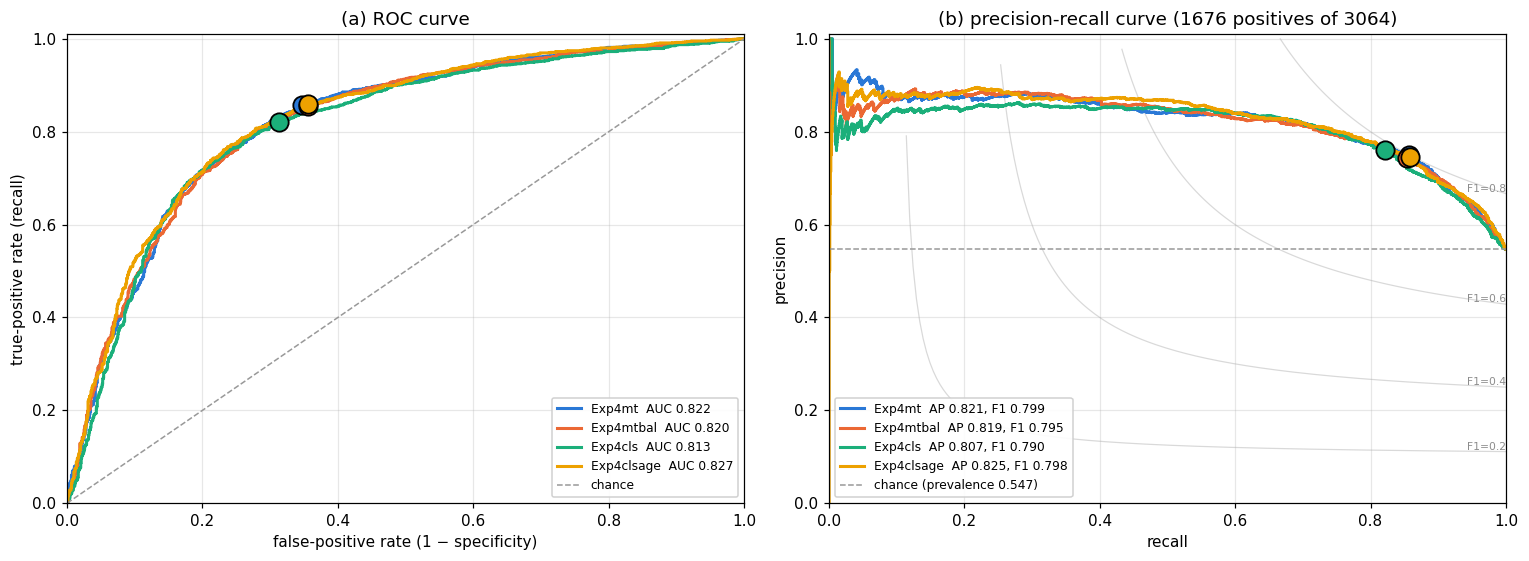

#### Figure 3.2(test). status_abnormal: ROC and precision-recall curves, TUAB test

274 TUAB-test recordings, 125 abnormal.

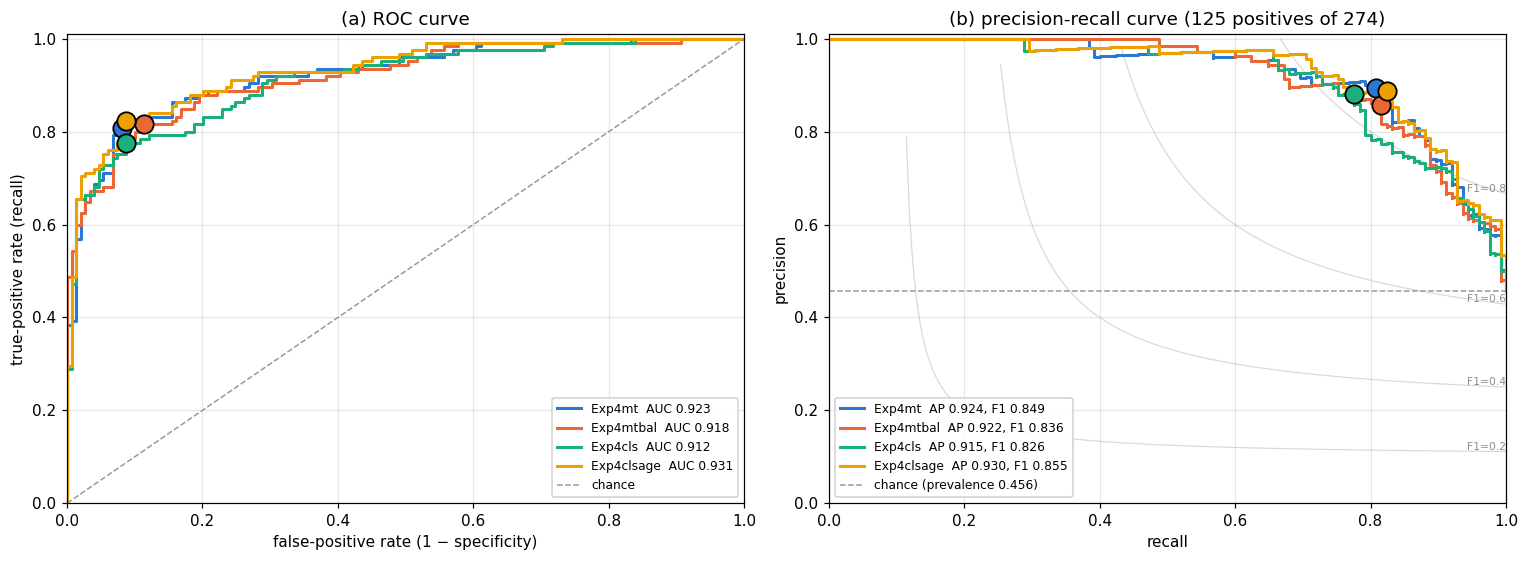

#### Figure 3.3. clinical_seizure: ROC and precision-recall curves, validation

185 positives of 2991 recordings (prevalence 0.062).

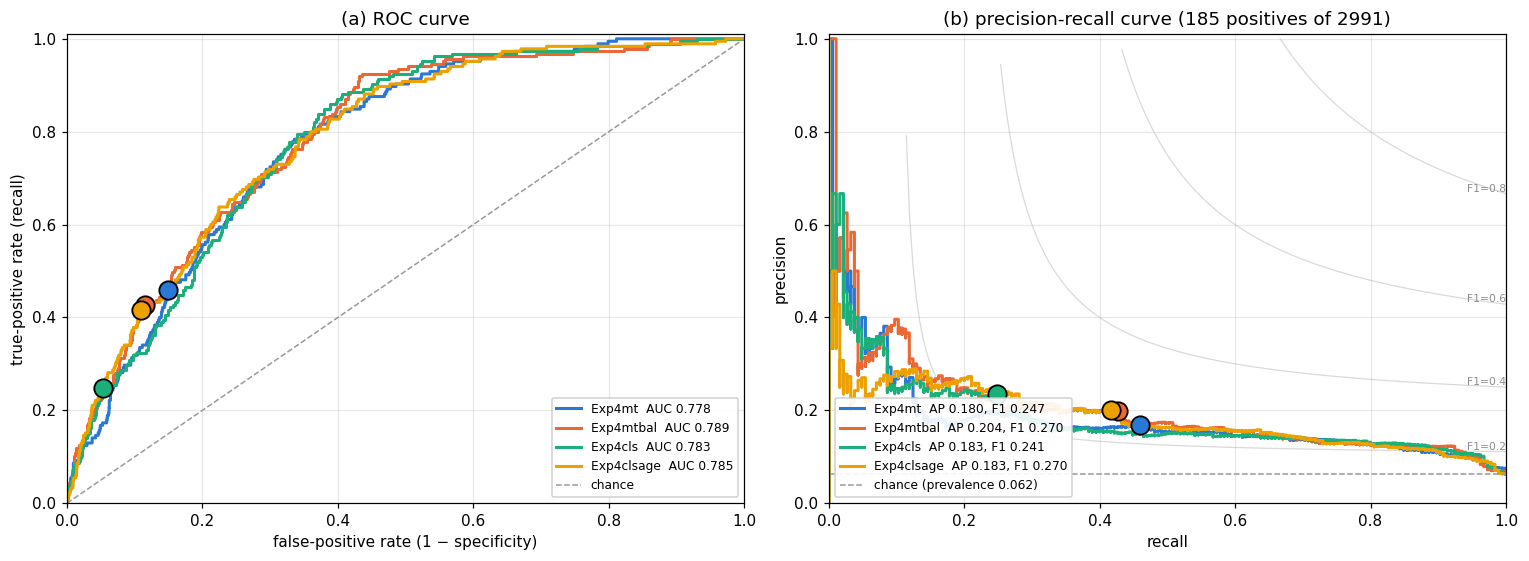

#### Figure 3.4. electrographic_seizure: ROC and precision-recall curves, validation

11 positives of 2991 recordings (prevalence 0.004).

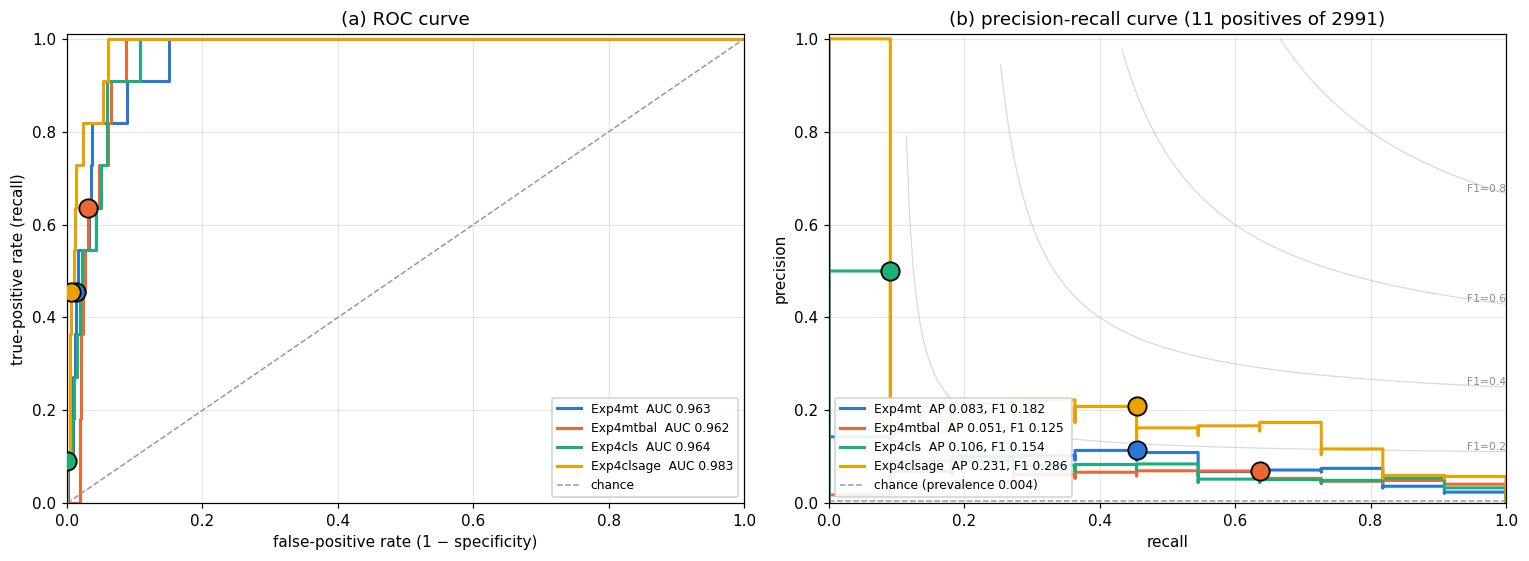

#### Figure 3.5. epilepsy: ROC and precision-recall curves, validation

46 positives of 2991 recordings (prevalence 0.015).

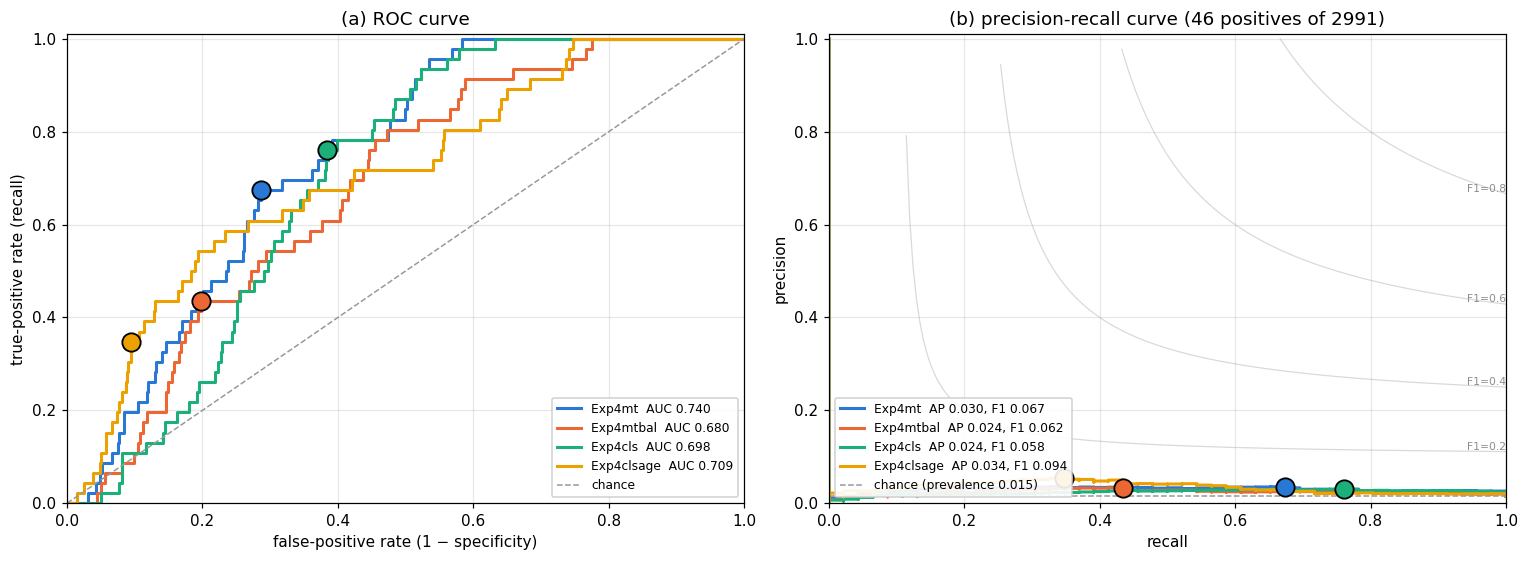

#### Figure 3.6. stroke: ROC and precision-recall curves, validation

93 positives of 2991 recordings (prevalence 0.031).

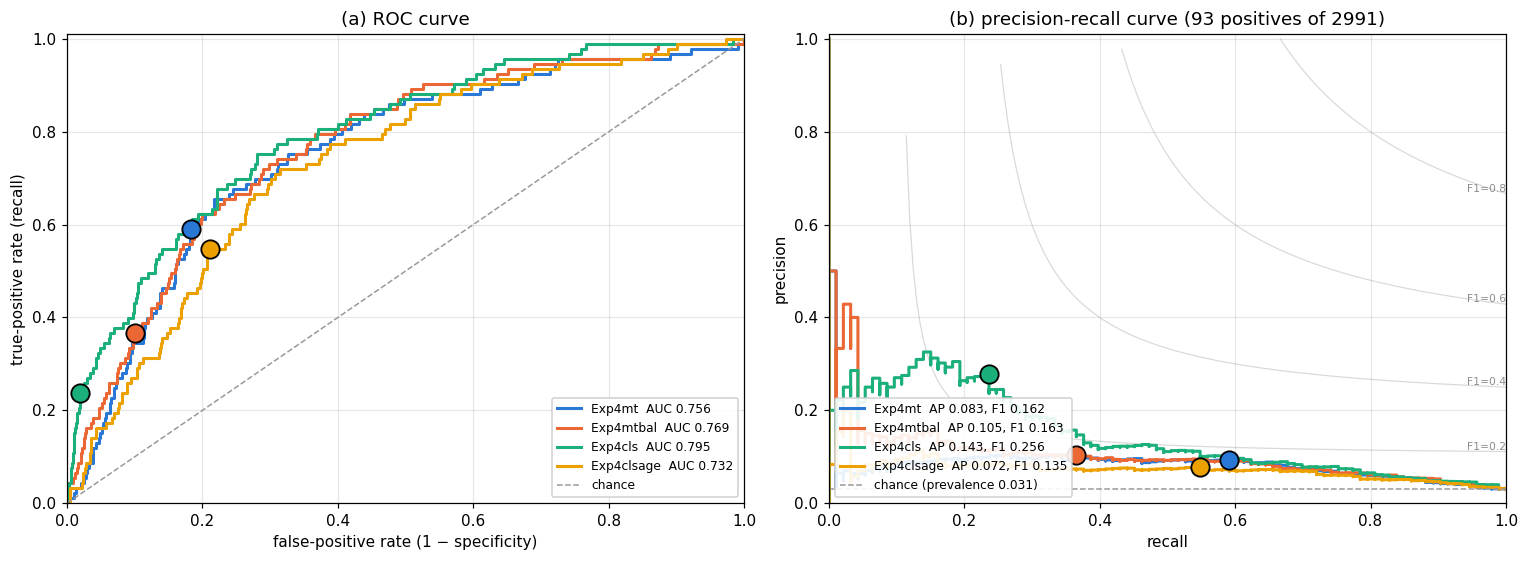

#### Figure 3.7. tbi: ROC and precision-recall curves, validation

50 positives of 2991 recordings (prevalence 0.017).

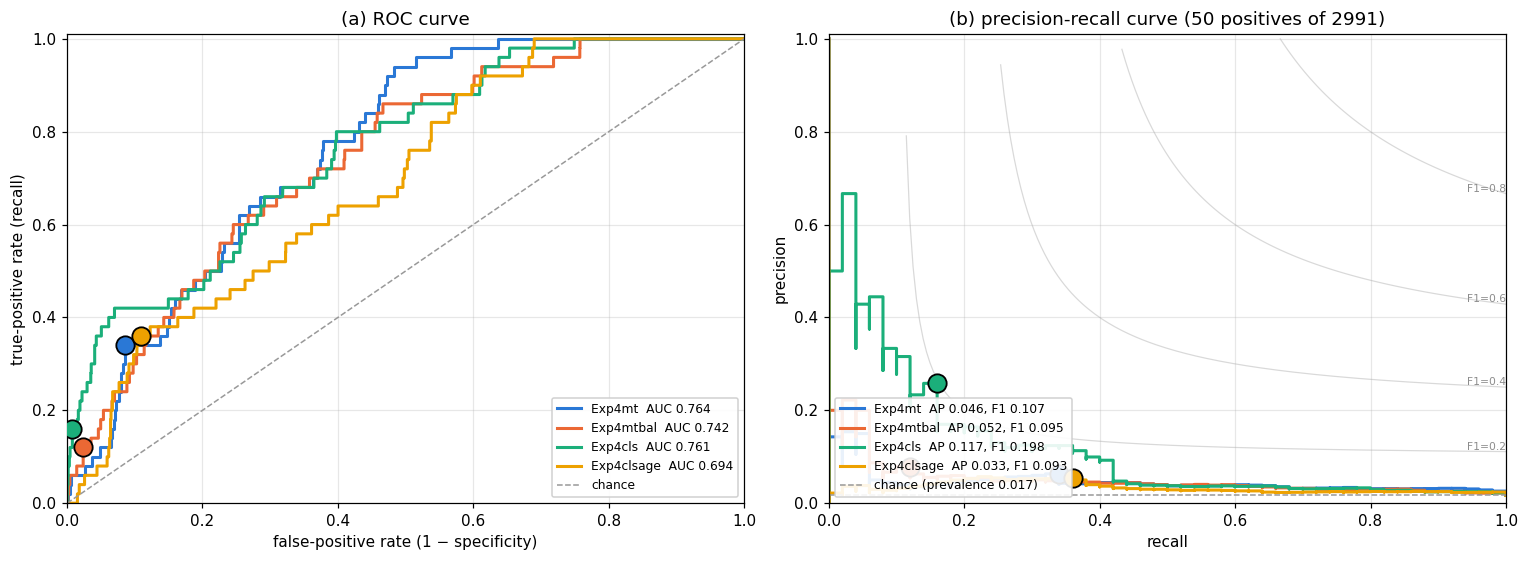

#### Figure 3.8. substance: ROC and precision-recall curves, validation

103 positives of 2991 recordings (prevalence 0.034).

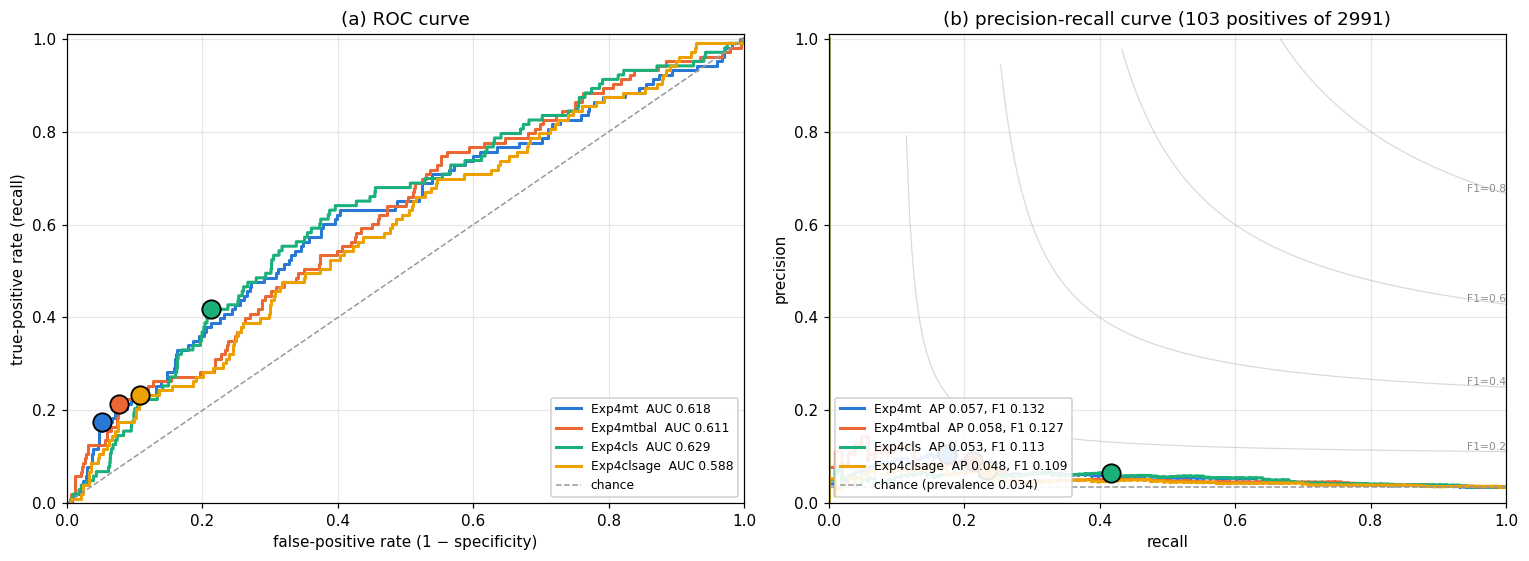

#### Figure 3.9. bipolar: ROC and precision-recall curves, validation

31 positives of 2991 recordings (prevalence 0.010).

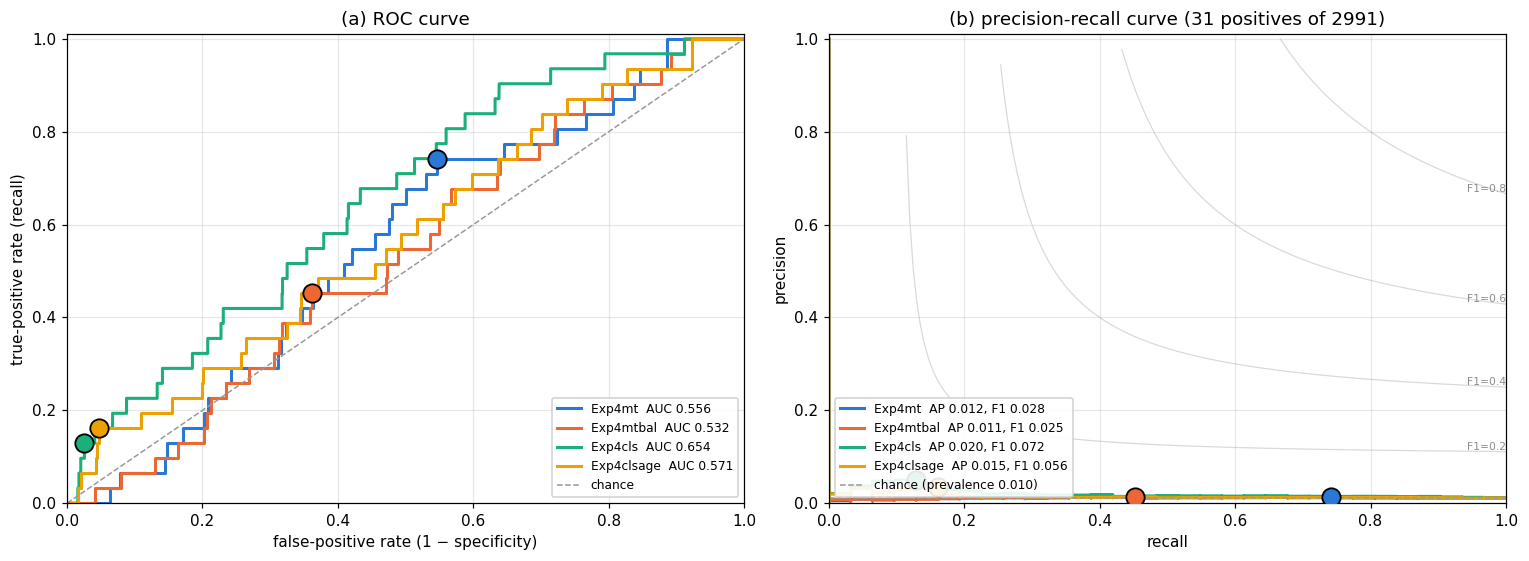

#### Figure 3.10. anxiety: ROC and precision-recall curves, validation

10 positives of 2991 recordings (prevalence 0.003).

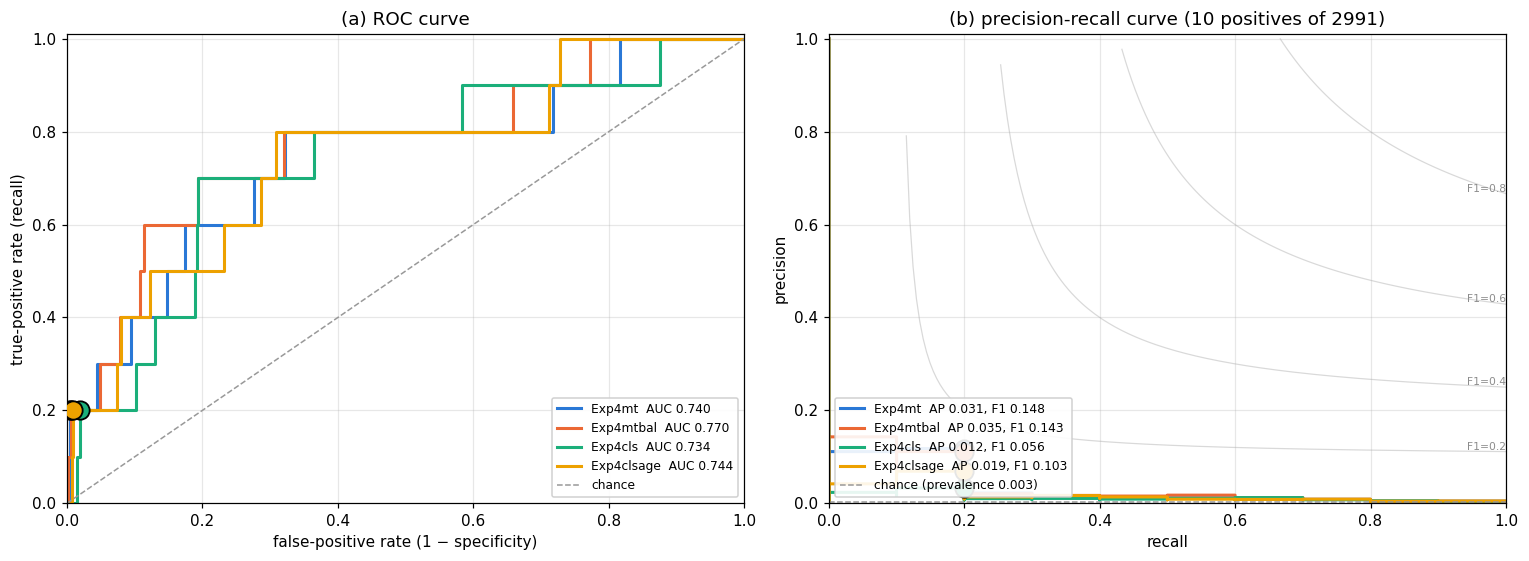

#### Figure 3.11. depression: ROC and precision-recall curves, validation

8 positives of 2991 recordings (prevalence 0.003).

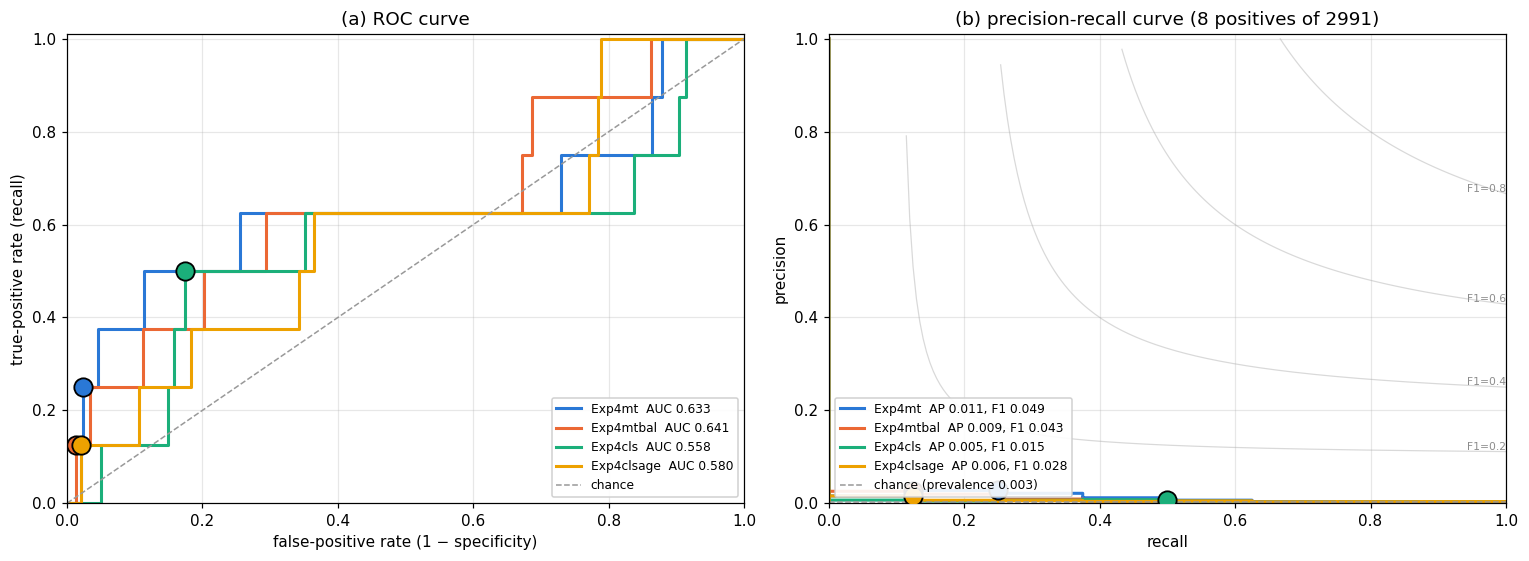

#### Figure 3.12. schizophrenia: ROC and precision-recall curves, validation

9 positives of 2991 recordings (prevalence 0.003).

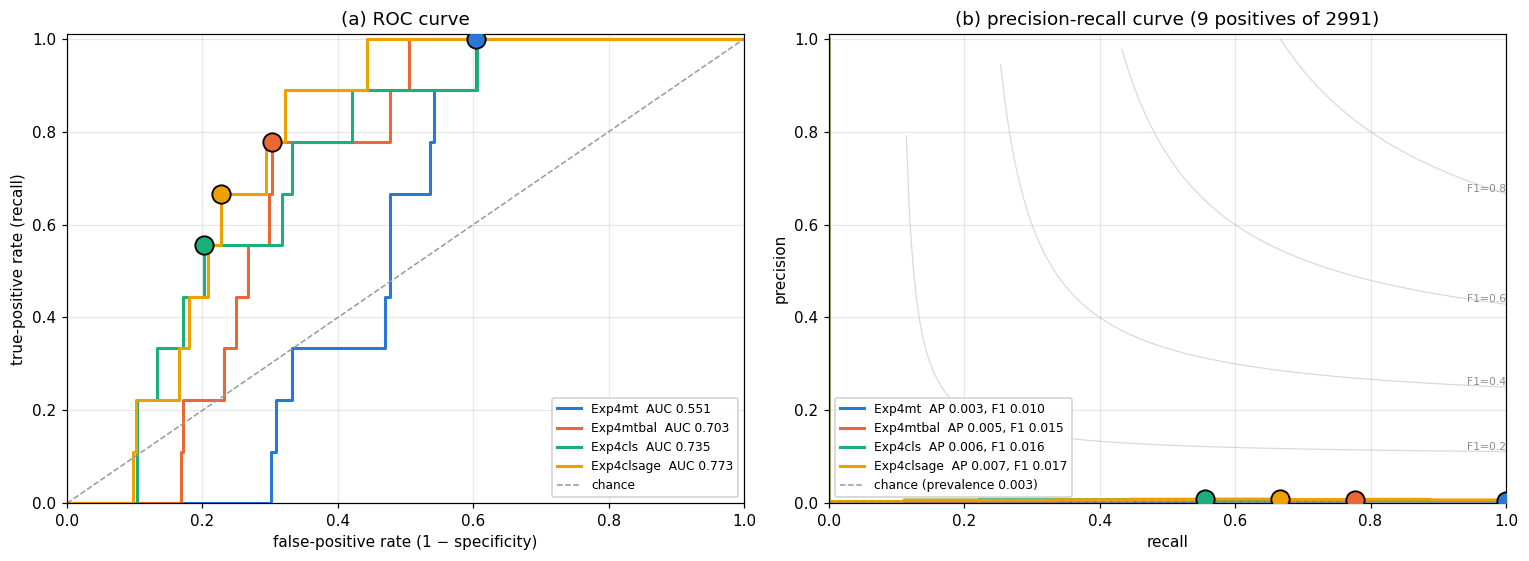

#### Figure 3.13. dementia: ROC and precision-recall curves, validation

10 positives of 2991 recordings (prevalence 0.003).

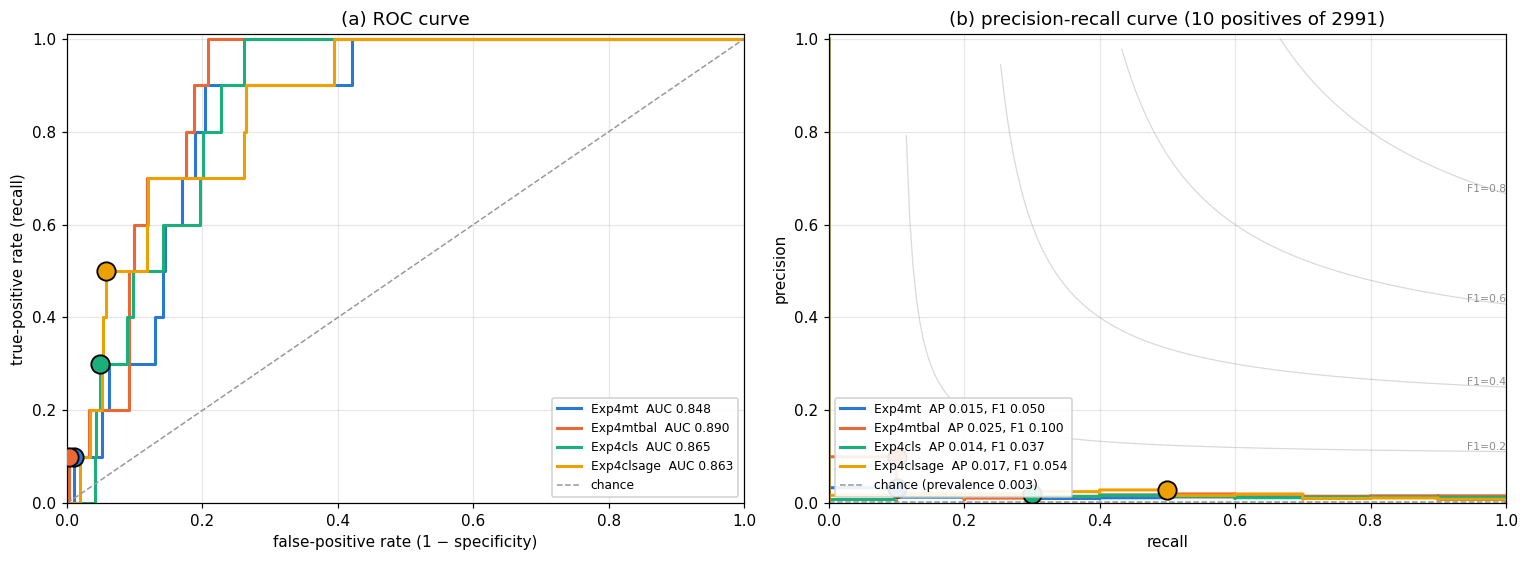

#### Figure 3.14. ms: ROC and precision-recall curves, validation

7 positives of 2991 recordings (prevalence 0.002).

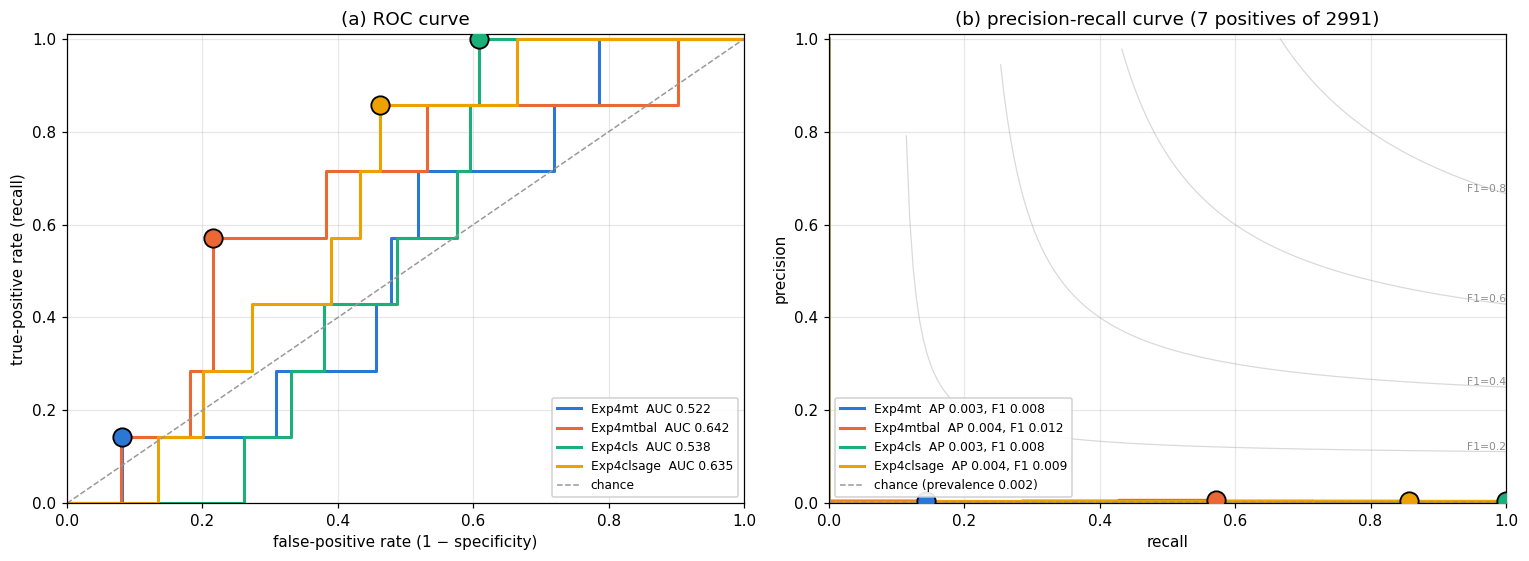

#### Figure 3.15. other: ROC and precision-recall curves, validation

12 positives of 2991 recordings (prevalence 0.004).

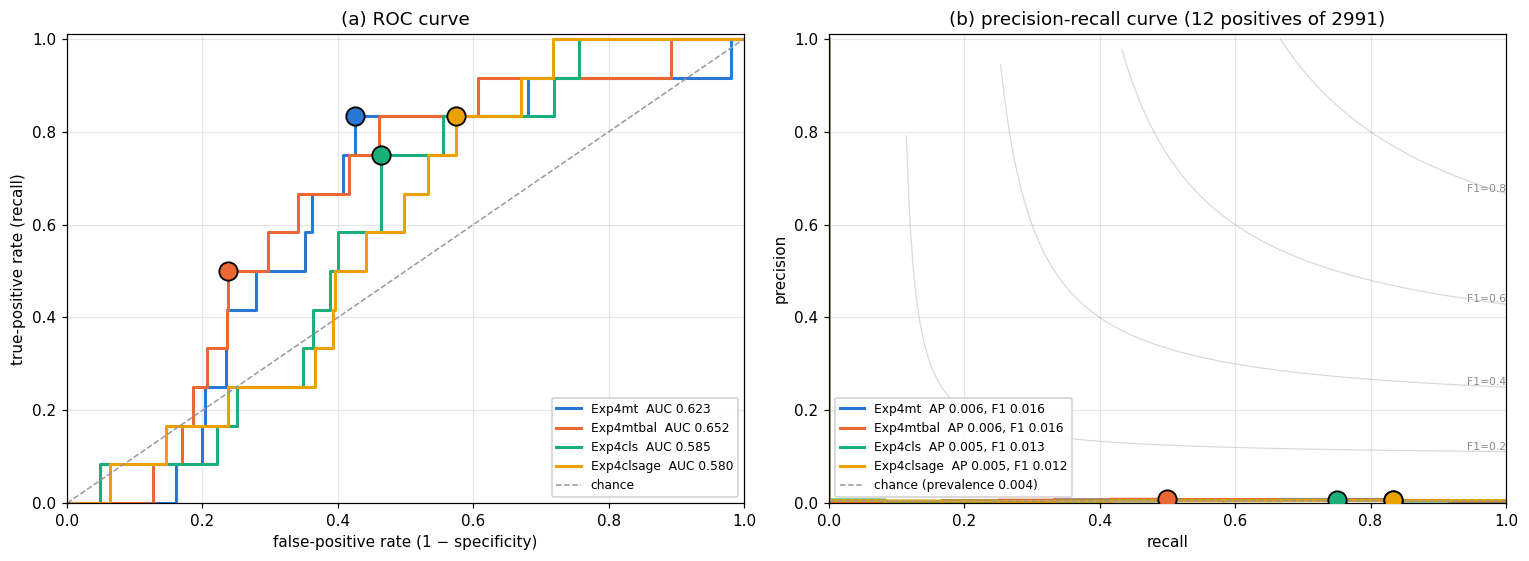

In [7]:
for k, g in enumerate(TARGETS):
    n = f"3.{k + 2}"
    s = val[(val.target == g) & (val.run == RUNS[0])].iloc[0]
    figure_heading(n, f"{g}: ROC and precision-recall curves, validation",
                   f"{int(s.positives)} positives of {int(s.n)} recordings (prevalence {s.prevalence:.3f}).", level=4)
    fig, axes = roc_pr_figure(PREDS, g, RUNS, "val")
    finish(fig, axes)
    if g == "status_abnormal":
        figure_heading(f"{n}(test)", "status_abnormal: ROC and precision-recall curves, TUAB test",
                       "274 TUAB-test recordings, 125 abnormal.", level=4)
        fig, axes = roc_pr_figure(PREDS, g, RUNS, "test")
        finish(fig, axes)

## 4. Reading the results

### Table 4.1. Classification-only runs against the age-predicting run with the same loss

Each later run minus `Exp4mtbal` (same class-balanced loss, same split), on validation: ROC-AUC, PR-AUC and
$F_1^{\star}$ of the status, and their macro means over the 13 groups (Eq. (2.8)). Positive = better than
`Exp4mtbal`. For a single rare group a difference below about 0.1 ROC-AUC is inside its bootstrap interval
(Table 3.1); the macro values average that noise down.

In [8]:
others = [r for r in RUNS if r not in ("Exp4mt", "Exp4mtbal")]
if not others:
    display(Markdown("*The classification-only runs are not scored yet.*"))
else:
    ref = val[val.run == "Exp4mtbal"].set_index("target")
    rows = {}
    for run in ["Exp4mt"] + others:
        r = val[val.run == run].set_index("target")
        d = {}
        for m, name in (("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"), ("best_f1", "best F1")):
            d[f"status {name}"] = r.loc["status_abnormal", m] - ref.loc["status_abnormal", m]
            gi = [g for g in r.index if g != "status_abnormal"]
            d[f"macro {name}"] = r.loc[gi, m].mean() - ref.loc[gi, m].mean()
        rows[f"{run} − Exp4mtbal"] = d
    display(numbered_table(pd.DataFrame(rows).T.map(lambda v: f"{v:+.3f}"), "4.1", "Classification-only runs versus Exp4mtbal"))

,status ROC-AUC,macro ROC-AUC,status PR-AUC,macro PR-AUC,status best F1,macro best F1
Exp4mt − Exp4mtbal,+0.001,-0.022,+0.002,-0.002,+0.004,+0.001
Exp4cls − Exp4mtbal,-0.007,-0.007,-0.012,+0.008,-0.006,+0.003
Exp4clsage − Exp4mtbal,+0.006,-0.011,+0.006,+0.006,+0.002,+0.005


**Reading Tables 3.1–3.3 and Figures 3.1–3.15.**

* **Status is a usable detector.** On validation the best F1 is 0.80 (Table 3.2) at a threshold near 0.43,
  with precision 0.75 and recall 0.86; at that point `Exp4mt` makes 481 false positives and 240 false negatives
  out of 3,064 recordings (error 23.5 %). On TUAB test the validation threshold carries over well (Table 3.3):
  F1 0.82 at the validation $t^{\star}$ against 0.84–0.85 when $t^{\star}$ is chosen on test, with 111 of 125
  abnormal recordings found, 34–36 false alarms and 14 misses (balanced error 17–18 %). Figure 3.2(test) shows the
  curves.
* **Clinical seizure and stroke are above the flag-everyone floor but far from a detector.** Clinical seizure
  reaches F1 0.25–0.27 against a floor of 0.12 (Figure 3.1(a)). Its best operating point flags about 400–500
  recordings to find 80 of the 185 seizure recordings: about 4–5 false alarms per hit (Table 3.2). Stroke reaches
  0.16 against 0.06. In Figure 3.3(b) precision stays below 0.4 at every recall.
* **A high ROC-AUC does not make a rare group detectable.** Electrographic seizure has ROC-AUC 0.96 (Table 3.1),
  yet its best F1 is 0.13–0.18, with an interval reaching 0.34. At prevalence 0.004, `Exp4mt`'s best point finds
  5 of the 11 positives with a false-positive rate of only 1.3 %, but that is still 39 false alarms. Dementia (ROC-AUC 0.85–0.89) is similar.
* **Many groups sit at the floor.** For bipolar, schizophrenia, MS and "other", $t^{\star}$ falls to about 0.01:
  the "best" F1 is then reached by flagging most recordings (e.g. schizophrenia: 1,800 false positives for 9
  positives), and it is barely above the flag-everyone floor (Figure 3.1(b)). These groups are not predicted.
* **The class-balanced loss changes the ranking, not the detection.** `Exp4mtbal` raises the macro ROC-AUC from
  0.70 to 0.72 (Table 3.1), but the macro best F1 stays at 0.09 (Table 3.2). Its gains are on groups too rare to
  give a usable F1.

**Reading Table 4.1: does the age prediction matter for pathology?**
* **Removing the age prediction does not improve the diagnosis groups.** `Exp4cls` (EEG only, no age loss)
  reaches a macro ROC-AUC of 0.715 against 0.722 for `Exp4mtbal` (Table 3.1). Its macro PR-AUC (0.053 vs 0.045) and
  macro best F1 (0.095 vs 0.092, Table 3.2) are about equal. Each run selected its epoch on this very metric, yet
  none passes `Exp4mtbal`; the age head neither costs nor helps the groups.
* **Without age, the status gets slightly worse.** `Exp4cls` has validation ROC-AUC 0.813 [0.797, 0.829] against
  0.820 [0.804, 0.836] (Table 3.1). On TUAB test at the validation threshold (Table 3.3) it finds 100 of 125
  abnormal recordings (25 missed, 28 false alarms; F1 0.79), against 111 found with 14 missed for the
  age-predicting runs (F1 0.82). Its test ROC-AUC is 0.912 against 0.918–0.923. Predicting age seems to act as a
  mild regularizer for the status head.
* **Knowing the age helps the status most, but within the noise.** `Exp4clsage` is the best status model: on
  validation ROC-AUC 0.827 [0.812, 0.841] and best F1 0.80; on TUAB test ROC-AUC 0.931 and F1 0.83 at the
  validation threshold (111 found, 31 false alarms, balanced error 16.0 % against 17.0–19.4 %, Table 3.3). The
  validation intervals of all four runs overlap, so this is a direction, not a proven gain. It fits the
  clinical rule that an EEG is abnormal relative to the patient's age: slowing that is normal at 80 is
  abnormal at 30.
* **The age input does not help the diagnosis groups.** `Exp4clsage`'s macro ROC-AUC is 0.711. It is best on
  electrographic seizure (ROC-AUC 0.983, best F1 0.29 with interval up to 0.52, Figure 3.4), but with 11
  positives. It loses on stroke (0.73 against 0.80 for `Exp4cls`) and TBI (0.69 against 0.76), where age is a
  strong prior that the model may over-use.
* **Single groups move by more than the runs differ overall.** `Exp4cls` reaches F1 0.26 on stroke and 0.20 on
  TBI against 0.16 / 0.10 for `Exp4mtbal` (Table 3.2, Figure 3.1). Their intervals are wide (stroke up to 0.35,
  TBI up to 0.32), so such per-group gains are not reproducible evidence until repeated with another seed.

**Conclusion.** The status is predicted well by every variant (validation ROC-AUC 0.81–0.83, TUAB test
0.91–0.93, about 80–89 % of abnormal test recordings found at the validation threshold). Neither dropping the age
prediction nor giving the model the age changes the diagnosis groups beyond their noise (macro ROC-AUC 0.70–0.72).
They stay limited by how rare their positives are: only clinical seizure, stroke and TBI clear the
flag-everyone floor by a useful margin, and none is a usable detector on its own (best F1 ≤ 0.27).